# Predicción de recaída en depresión

Proyecto sencillo de aprendizaje automático con datos simulados.

> **Aviso educativo:** este proyecto usa datos ficticios. El PHQ-9 es una herramienta de cribado, no un diagnóstico. Si en un caso real el ítem 9 (pensamientos de muerte) es mayor que 0, se requiere valoración clínica inmediata. No uses datos de pacientes identificables.

**¿Qué vas a aprender?**

- Crear un conjunto de datos pequeño y entender sus columnas.
- Separar datos de entrenamiento y de prueba.
- Entrenar una regresión logística.
- Evaluar el modelo con métricas básicas.
- Interpretar sus resultados con lenguaje sencillo.

## 1. Librerías

Usaremos `pandas` para la tabla de datos, `scikit-learn` para el modelo y `matplotlib` para los gráficos. En Google Colab ya vienen instaladas.

In [1]:
# Si trabajas en Colab, esta línea no es necesaria, pero no molesta.
%pip install -q pandas scikit-learn matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from IPython.display import display, Markdown

SEMILLA = 42
print('Librerías listas.')


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Librerías listas.


## 2. Datos simulados

Vamos a inventar **300 pacientes**. Cada fila es una persona. Las columnas son:

| Columna | Qué significa |
|---|---|
| `edad` | Edad en años. |
| `sexo_femenino` | 1 si es mujer, 0 si no. |
| `phq9_alta` | Puntaje PHQ-9 al alta (0 a 9: en remisión). |
| `episodios_previos` | Número de episodios depresivos anteriores. |
| `adherencia` | Qué tanto sigue el tratamiento (0 a 10). |
| `apoyo_social` | Apoyo percibido (0 a 10). |
| `horas_sueno` | Horas de sueño promedio. |
| `recaida_6m` | 1 si recayó en los primeros 6 meses; 0 si no. |

Para que el ejercicio tenga sentido, simulamos un riesgo y marcamos como recaída al 20% de pacientes con mayor riesgo. Así quedan **60 recaídas** y el modelo tiene un patrón que puede aprender.

In [2]:
rng = np.random.default_rng(SEMILLA)
n = 300

datos = pd.DataFrame({
    'edad': rng.integers(18, 71, n),
    'sexo_femenino': rng.integers(0, 2, n),
    'phq9_alta': rng.integers(0, 10, n),
    'episodios_previos': rng.integers(0, 6, n),
    'adherencia': rng.integers(0, 11, n),
    'apoyo_social': rng.integers(0, 11, n),
    'horas_sueno': rng.uniform(4, 9, n).round(1),
})

riesgo = (
    0.8 * datos.phq9_alta
    + 0.6 * datos.episodios_previos
    - 0.5 * datos.adherencia
    - 0.4 * datos.apoyo_social
    - 0.3 * (datos.horas_sueno - 6)
    + rng.normal(0, 2, n)
)
datos['recaida_6m'] = (riesgo > np.quantile(riesgo, 0.8)).astype(int)

display(datos.head())
display(datos.recaida_6m.value_counts().rename('pacientes'))

,edad,sexo_femenino,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno,recaida_6m
0,22,0,6,0,9,5,6.3,0
1,59,1,7,0,5,2,5.3,0
2,52,0,7,1,10,2,4.2,1
3,41,1,1,5,8,3,6.4,0
4,40,1,8,2,7,6,8.8,0


recaida_6m
0    240
1     60
Name: pacientes, dtype: int64

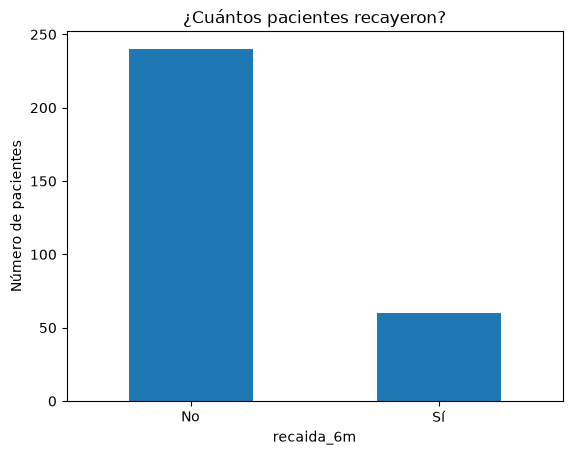

In [3]:
datos.recaida_6m.value_counts().sort_index().plot(kind='bar')
plt.title('¿Cuántos pacientes recayeron?')
plt.xlabel('recaida_6m')
plt.ylabel('Número de pacientes')
plt.xticks([0, 1], ['No', 'Sí'], rotation=0)
plt.show()

In [4]:
display(Markdown(f"""**Cómo leer esto:** hay **{len(datos)}** pacientes. De ellos, **{int(datos.recaida_6m.sum())}** recayeron y **{int((datos.recaida_6m == 0).sum())}** no. La variable `recaida_6m` es la que el modelo intentará predecir."""))

**Cómo leer esto:** hay **300** pacientes. De ellos, **60** recayeron y **240** no. La variable `recaida_6m` es la que el modelo intentará predecir.

## 3. Exploración rápida

Antes de entrenar un modelo, conviene mirar si las variables se comportan como esperamos. Comparamos los promedios entre quienes recayeron y quienes no.

,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno
recaida_6m,,,,,
0,4.12,2.41,5.53,5.38,6.58
1,6.77,2.98,3.20,3.13,6.46


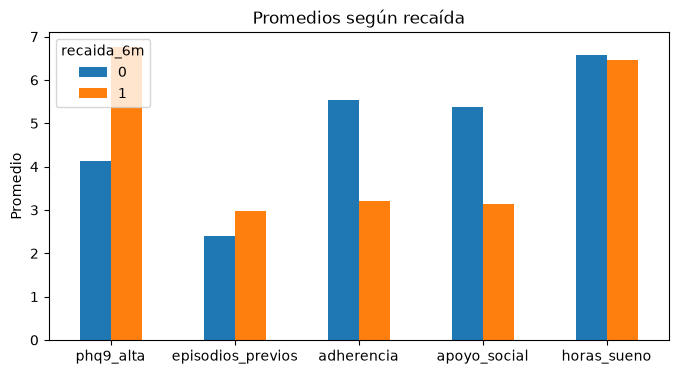

In [5]:
tabla = datos.groupby('recaida_6m')[
    ['phq9_alta', 'episodios_previos', 'adherencia', 'apoyo_social', 'horas_sueno']
].mean().round(2)
display(tabla)

tabla.T.plot(kind='bar', figsize=(8, 4))
plt.title('Promedios según recaída')
plt.ylabel('Promedio')
plt.xticks(rotation=0)
plt.show()

In [6]:
display(Markdown("""**Cómo leer esto:** los pacientes que recayeron tienen, en promedio, un PHQ-9 al alta más alto, más episodios previos, menos adherencia y menos apoyo social. Eso no prueba causalidad, pero sí sugiere que esas variables pueden ayudar a predecir."""))

**Cómo leer esto:** los pacientes que recayeron tienen, en promedio, un PHQ-9 al alta más alto, más episodios previos, menos adherencia y menos apoyo social. Eso no prueba causalidad, pero sí sugiere que esas variables pueden ayudar a predecir.

## 4. Separar entrenamiento y prueba

Entrenamos con el 80% de los datos y evaluamos con el 20% restante. Usamos `stratify=y` para que la proporción de recaídas sea parecida en ambos grupos.

In [7]:
X = datos.drop(columns='recaida_6m')
y = datos['recaida_6m']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

Entrenamiento: (240, 7)
Prueba: (60, 7)


## 5. Entrenar la regresión logística

La regresión logística combina las variables para estimar la **probabilidad** de que un paciente recaiga. Estandarizamos las variables para que todas estén en una escala parecida.

In [8]:
modelo = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
proba = modelo.predict_proba(X_test)[:, 1]
print('Modelo entrenado.')

Modelo entrenado.


## 6. Evaluar el modelo

No basta con mirar la exactitud. Como hay pocas recaídas, también revisamos el ROC-AUC, la matriz de confusión y el reporte por clase.

In [9]:
print('Exactitud:', round(accuracy_score(y_test, pred), 2))
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 2))
print('Matriz de confusión:')
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, zero_division=0))

Exactitud: 0.83
ROC-AUC: 0.86
Matriz de confusión:
[[44  4]
 [ 6  6]]
              precision    recall  f1-score   support

           0       0.88      0.92      0.90        48
           1       0.60      0.50      0.55        12

    accuracy                           0.83        60
   macro avg       0.74      0.71      0.72        60
weighted avg       0.82      0.83      0.83        60



In [10]:
display(Markdown(f"""**Cómo leer esto:** la exactitud es **{accuracy_score(y_test, pred):.0%}** y el ROC-AUC es **{roc_auc_score(y_test, proba):.2f}**. Un ROC-AUC de 0.5 equivale al azar; 1.0 sería perfecto. La matriz de confusión muestra los aciertos y errores: filas = valor real, columnas = predicción. La sensibilidad (recall para la clase 1) indica qué proporción de las recaídas reales logramos detectar."""))

**Cómo leer esto:** la exactitud es **83%** y el ROC-AUC es **0.86**. Un ROC-AUC de 0.5 equivale al azar; 1.0 sería perfecto. La matriz de confusión muestra los aciertos y errores: filas = valor real, columnas = predicción. La sensibilidad (recall para la clase 1) indica qué proporción de las recaídas reales logramos detectar.

## 7. ¿Qué variables pesan más?

Los coeficientes indican la dirección del efecto: positivos aumentan el riesgo y negativos lo reducen. Como estandarizamos, se pueden comparar entre sí.

apoyo_social        -1.31
adherencia          -1.18
edad                -0.14
sexo_femenino        0.00
horas_sueno          0.02
episodios_previos    0.51
phq9_alta            1.62
dtype: float64

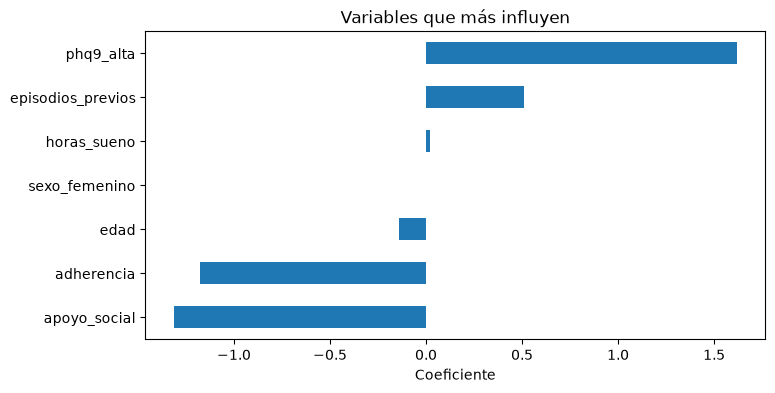

In [11]:
coeficientes = pd.Series(
    modelo.named_steps['logisticregression'].coef_[0],
    index=X.columns
).sort_values()

display(coeficientes.round(2))
coeficientes.plot(kind='barh', figsize=(8, 4))
plt.title('Variables que más influyen')
plt.xlabel('Coeficiente')
plt.show()

In [12]:
display(Markdown("""**Cómo leer esto:** `phq9_alta` y `episodios_previos` empujan el riesgo hacia arriba. `adherencia` y `apoyo_social` lo empujan hacia abajo. Un coeficiente grande no significa que la variable sea la causa; solo que aporta información en este modelo y en estos datos simulados."""))

**Cómo leer esto:** `phq9_alta` y `episodios_previos` empujan el riesgo hacia arriba. `adherencia` y `apoyo_social` lo empujan hacia abajo. Un coeficiente grande no significa que la variable sea la causa; solo que aporta información en este modelo y en estos datos simulados.

## 8. Predecir un paciente nuevo

Creamos dos pacientes de ejemplo y pedimos la probabilidad de recaída. La probabilidad no es una fecha exacta ni un diagnóstico.

In [13]:
nuevo = pd.DataFrame({
    'edad': [35, 52],
    'sexo_femenino': [1, 0],
    'phq9_alta': [8, 3],
    'episodios_previos': [4, 1],
    'adherencia': [4, 9],
    'apoyo_social': [3, 8],
    'horas_sueno': [5.5, 7.5],
})

nuevo['riesgo'] = modelo.predict_proba(nuevo)[:, 1].round(2)
nuevo['mensaje'] = nuevo.riesgo.apply(
    lambda p: 'Riesgo alto' if p >= 0.5 else 'Riesgo bajo'
)
display(nuevo)

,edad,sexo_femenino,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno,riesgo,mensaje
0,35,1,8,4,4,3,5.5,0.75,Riesgo alto
1,52,0,3,1,9,8,7.5,0.00,Riesgo bajo


In [14]:
display(Markdown("""**Cómo leer esto:** el primer paciente tiene un riesgo estimado más alto. El umbral de 0.5 es una decisión arbitraria: en un contexto real se elegiría según el costo de no detectar una recaída. El modelo orienta, pero no reemplaza el juicio clínico."""))

**Cómo leer esto:** el primer paciente tiene un riesgo estimado más alto. El umbral de 0.5 es una decisión arbitraria: en un contexto real se elegiría según el costo de no detectar una recaída. El modelo orienta, pero no reemplaza el juicio clínico.

## 9. Ejercicios

1. Cambia el umbral de 0.5 a 0.4 y explica qué pasa con la sensibilidad.
2. Quita la variable `adherencia` y compara el ROC-AUC.
3. Prueba `LogisticRegression(class_weight='balanced')` y comenta el resultado.
4. Agrega una variable nueva y observa si mejora el modelo.
5. Cambia el tamaño de prueba a 30% y compara las métricas.

## 10. Errores comunes

- **Entrenar y evaluar con los mismos datos:** las métricas se ven mejores de lo que son.
- **Mirar solo la exactitud:** con clases desbalanceadas, un modelo puede acertar mucho y no detectar ninguna recaída.
- **Confundir probabilidad con certeza:** un riesgo de 0.70 no significa que la persona vaya a recaer seguro.
- **Creer que el modelo diagnostica:** es una herramienta de apoyo, no un diagnóstico.
- **Usar datos reales sin anonimizar:** nunca incluyas nombres, DNI ni historias clínicas identificables.
- **No revisar los datos:** valores perdidos, fechas mal escritas o columnas mal nombradas cambian el resultado.

## 11. Conclusión

Aprendiste a crear un dataset pequeño, explorarlo, separar entrenamiento y prueba, entrenar una regresión logística, evaluarla e interpretar sus coeficientes. Es un proyecto educativo: con datos reales harían falta más variables, validación clínica, revisión ética y un estudio de utilidad.

> **Recordatorio:** el PHQ-9 es cribado, no diagnóstico. Los datos de este cuaderno son ficticios.

In [15]:
assert len(datos) == 300
assert datos.recaida_6m.sum() == 60
assert len(X_train) + len(X_test) == 300
assert 0 <= accuracy_score(y_test, pred) <= 1
assert 0 <= roc_auc_score(y_test, proba) <= 1
print('Proyecto verificado correctamente.')

Proyecto verificado correctamente.
